## Setup (run this first)
This cell finds the project files automatically: current folder, then the group GitHub repo, then a shared Drive folder, then a zip upload. Everyone (group members and the instructor) can run it without editing paths.

In [ ]:
# ---- Setup: works for any group member, the instructor, Colab or a laptop ------------------------------
# Order tried: (1) the files are already in the current folder, (2) Member3_Baseline_NLP.zip is already uploaded
# (Colab file panel or next to this notebook), (3) the shared Google Drive zip (downloaded, no sign-in),
# (4) the group GitHub repo, (5) an already-mounted Drive folder, (6) you upload the zip when asked. Nothing needs editing.
import os, sys, glob, zipfile, subprocess
REPO_URL = os.environ.get("REPO_URL", "https://github.com/jijjira/anlp-at2b-study-to-career.git")
DRIVE_DIR = "/content/drive/MyDrive/ANLP AT2B"
DRIVE_ZIP_ID = "1pgnI7O_CHeXK7RRtrGqA-XA7dKOvW6G_"   # Member3_Baseline_NLP.zip in the shared Drive folder
NEEDED = ["skill_extractor.py", "skill_extractor_v2.py", "analysis.py", "evaluate.py", "gold_annotations.py",
          "job_cleaned.csv", "skills_dictionary.csv", "normalisation.py", "extra_aliases_reviewed.csv",
          "discovery_candidates_raw.csv", "gold_split.json"]
try:
    import google.colab; IN_COLAB = True
except ImportError:
    IN_COLAB = False
def have_all(d="."): return all(os.path.exists(os.path.join(d, f)) for f in NEEDED)
def use(folder): os.chdir(folder); print("Using folder:", os.getcwd())
def code_folder(root):
    hits = glob.glob(os.path.join(root, "**", "skill_extractor_v2.py"), recursive=True)
    return os.path.dirname(hits[0]) if hits else None
def from_zip(z):
    out = "/content/m3" if IN_COLAB else os.path.join(os.path.dirname(os.path.abspath(z)), "_m3")
    zipfile.ZipFile(z).extractall(out); f = code_folder(out)
    if f: use(f)
START = os.getcwd()
if not have_all():                                   # (2) a zip that is already there
    for z in glob.glob("*.zip") + glob.glob("/content/*.zip"):
        if "Member3" in os.path.basename(z) and not have_all(): from_zip(z)
if not have_all():                                   # (3) the public Drive zip (one file, no sign-in needed)
    try:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdown"], check=False)
        import gdown
        zdir = "/content" if IN_COLAB else START
        zp = gdown.download(id=DRIVE_ZIP_ID, output=os.path.join(zdir, "Member3_Baseline_NLP.zip"), quiet=True)
        if zp and zipfile.is_zipfile(zp): from_zip(zp)
        else: print("Could not download the zip from Drive, trying the next option.")
    except Exception:
        print("Could not download the zip from Drive, trying the next option.")
if not have_all():                                   # (4) group repo (works only if it is public or you are signed in)
    dest = "/content/_repo" if IN_COLAB else os.path.join(START, "_repo")
    if not os.path.exists(dest):
        env = dict(os.environ, GIT_TERMINAL_PROMPT="0")
        r = subprocess.run(["git", "clone", "--depth", "1", REPO_URL, dest], capture_output=True, text=True, env=env)
        if r.returncode != 0: print("Could not clone the repo (it may be private), trying the next option.")
    f = code_folder(dest) if os.path.exists(dest) else None
    if f: use(f)
if not have_all() and os.path.isdir(DRIVE_DIR) and have_all(DRIVE_DIR): use(DRIVE_DIR)   # (5) Drive, only if already mounted
if not have_all() and IN_COLAB:                      # (6) ask for the zip; never save into the Drive mount
    os.chdir("/content")
    print("Please choose Member3_Baseline_NLP.zip (from the group Drive or the submission).")
    from google.colab import files
    for name in files.upload():
        if name.endswith(".zip") and not have_all(): from_zip(os.path.join("/content", name))
sys.path.insert(0, os.getcwd())
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "spacy", "pymupdf", "reportlab"], check=False)
missing = [f for f in NEEDED if not os.path.exists(f)]
print("Working folder:", os.getcwd()); print("Missing files:", missing if missing else "none, good to go")


# 04 · Baseline++, innovation experiments (Member 3)
**Goal.** The poster was marked down for *limited innovation* and *thin technical evaluation*. This notebook upgrades the Step-3 PhraseMatcher baseline into a **measured, requirement-aware extractor** and reports what actually worked, including what did *not*.

Contributions (all rule-based, explainable, reproducible; `random seed = 36118`):
1. **Held-out gold standard** (30 ads, stratified, 4 label tiers) → first real P/R/F1 for the project.
2. **Ablation S0→S5** with paired-bootstrap CIs.
3. **Requirement-strength tagging** (required / duty / preferred / company) → demand-weighted career profiles.
4. **Dictionary discovery** by list-context mining + human review (dev jobs only, no leakage).
5. **Honest error analysis** and a quantified ceiling for a dictionary method (implicit + out-of-dictionary skills) → the target for Member 4's semantic layer.
6. **Marginal-gain "learn next" demo** that turns the profiles into a recommendation signal for the UI.

> **Caveat.** Gold labels were produced by one annotator (an LLM) blind to extractor output, so scores are *silver-standard*; n = 30 ads. Treat absolute numbers as indicative and the *relative* ablation as the finding.

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.width', 180); pd.set_option('display.max_colwidth', 80)
from analysis import *
from evaluate import run, bootstrap, systems
from gold_annotations import GOLD
jobs.career_category.value_counts()

career_category
AI Engineer       275
ML Engineer       202
Data Scientist    127
Data Engineer      57
Data Analyst       27
Name: count, dtype: int64

## 1 · Gold standard design
Stratified sample (6 ads per career, seed 36118) drawn **before** any tuning; discovery/tuning code excludes these ads. Each skill mention is labelled **R** (explicit, demanded), **P** (explicit but preferred), **I** (implicit/paraphrase, needs semantics), **OTHER** (real skill outside our dictionary).

In [3]:
tot = pd.Series({k: sum(len(GOLD[r][k]) for r in ROWS) for k in ['R','P','I','OTHER']})
print('Gold ads:', len(ROWS)); tot.to_frame('labels')

Gold ads: 30


,labels
R,211
P,39
I,43
OTHER,49


## 2 · Ablation with paired bootstrap
S0 = Step-3 baseline. S1 guard only, S2 section filter only, S3 both, S4 + reviewed aliases, S5 + plural/singular variants.

In [4]:
preds, res = run()
res.round(3)

TP    FP    FN      P      R     F1
extended (132 + reviewed extras) S0 Baseline (v1: all PhraseMatcher hits)  211.0  23.0  39.0  0.902  0.844  0.872
                                 S1 + URL/ambiguity guard only             211.0  23.0  39.0  0.902  0.844  0.872
                                 S2 + section-aware demand filter          209.0  17.0  41.0  0.925  0.836  0.878
                                 S3 = S1 + S2 (context-aware)              209.0  17.0  41.0  0.925  0.836  0.878
                                 S4 + reviewed extra aliases               244.0  26.0   6.0  0.904  0.976  0.938
                                 S5 + plural/singular variants             246.0  26.0   4.0  0.904  0.984  0.943
base dictionary only (132)       S0 Baseline (v1: all PhraseMatcher hits)  211.0  23.0  28.0  0.902  0.883  0.892
                                 S1 + URL/ambiguity guard only             211.0  23.0  28.0  0.902  0.883  0.892
                                 S2 + section-aware demand filter          209.0  17.0  30.0  0.925  0.874  0.899
                                 S3 = S1 + S2 (context-aware)              209.0  17.0  30.0  0.925  0.874  0.899
                                 S4 + reviewed extra aliases               234.0  25.0   5.0  0.903  0.979  0.940
                                 S5 + plural/singular variants             236.0  25.0   3.0  0.904  0.987  0.944

In [5]:
_, res_noai = run(drop_ai=True)
print('Annotation-sensitivity check: drop the vaguest label ("Artificial Intelligence")')
res_noai.round(3)

Annotation-sensitivity check: drop the vaguest label ("Artificial Intelligence")


TP    FP    FN      P      R     F1
extended (132 + reviewed extras) S0 Baseline (v1: all PhraseMatcher hits)  210.0  21.0  25.0  0.909  0.894  0.901
                                 S1 + URL/ambiguity guard only             210.0  21.0  25.0  0.909  0.894  0.901
                                 S2 + section-aware demand filter          209.0  17.0  26.0  0.925  0.889  0.907
                                 S3 = S1 + S2 (context-aware)              209.0  17.0  26.0  0.925  0.889  0.907
                                 S4 + reviewed extra aliases               229.0  18.0   6.0  0.927  0.974  0.950
                                 S5 + plural/singular variants             231.0  18.0   4.0  0.928  0.983  0.955
base dictionary only (132)       S0 Baseline (v1: all PhraseMatcher hits)  210.0  21.0  14.0  0.909  0.938  0.923
                                 S1 + URL/ambiguity guard only             210.0  21.0  14.0  0.909  0.938  0.923
                                 S2 + section-aware demand filter          209.0  17.0  15.0  0.925  0.933  0.929
                                 S3 = S1 + S2 (context-aware)              209.0  17.0  15.0  0.925  0.933  0.929
                                 S4 + reviewed extra aliases               219.0  17.0   5.0  0.928  0.978  0.952
                                 S5 + plural/singular variants             221.0  17.0   3.0  0.929  0.987  0.957

In [6]:
names = list(preds)
rows = []
for a, b in [(0,3),(3,4),(4,5),(0,5)]:
    r = bootstrap(preds, names[a], names[b]); rows.append({'from': names[a][:2], 'to': names[b][:2], 'ΔF1': r['delta'], '95% CI': r['delta_CI'], 'P(Δ≤0)': r['p_delta_le_0']})
pd.DataFrame(rows)

,from,to,ΔF1,95% CI,P(Δ≤0)
0,S0,S3,0.006,"(-0.006, 0.021)",0.1810
1,S3,S4,0.060,"(0.027, 0.095)",0.0000
2,S4,S5,0.004,"(0.0, 0.011)",0.1265
3,S0,S5,0.071,"(0.039, 0.104)",0.0000


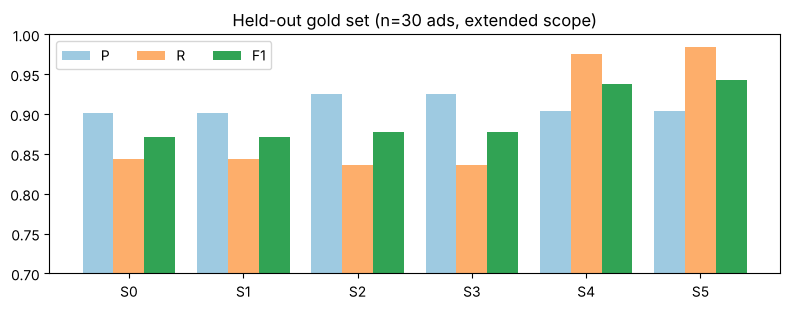

In [7]:
ext = res.loc['extended (132 + reviewed extras)']
fig, ax = plt.subplots(figsize=(8,3.2)); x = np.arange(len(ext)); w=.27
for i,(m,c) in enumerate([('P','#9ecae1'),('R','#fdae6b'),('F1','#31a354')]): ax.bar(x+(i-1)*w, ext[m], w, label=m, color=c)
ax.set_xticks(x); ax.set_xticklabels([n[:2] for n in ext.index]); ax.set_ylim(.7,1); ax.legend(ncol=3); ax.set_title('Held-out gold set (n=30 ads, extended scope)'); plt.tight_layout(); plt.show()

**Reading the table honestly.**
* The big, significant gain (**F1 0.872 → 0.943 overall (S0→S5, Δ = +0.071, CI 0.039-0.104)**, Δ CI excludes 0) comes from **S4: reviewed aliases** (recall 0.84 → 0.98 incl. morphology), i.e. the *dictionary was the bottleneck*, not the matcher.
* The **section/ambiguity filter (S1-S3) does not move F1** (Δ = +0.006, CI −0.006…0.021 spans 0). It trades 2 true positives for 6 fewer false positives. Its value is a different output (demand strength), evaluated in §3, we do not claim an accuracy gain for it.
* Morphology (S5) adds a small, borderline gain (CI lower bound 0.000).

## 3 · Requirement-strength tagging → demand-weighted profiles
Every mention inherits the strength of the ad section it sits in. Weights are hyper-parameters (required 1, duty .75, preferred .5, unlabelled .5, company 0).

In [8]:
S, RAW = corpus_tables(); P = profiles(S, RAW)
dist = pd.Series([v for d in S for v in d.values()]).value_counts()
(dist/dist.sum()).round(3).to_frame('share of skill-mentions')

,share of skill-mentions
required,0.455
duty,0.319
preferred,0.148
unlabelled,0.045
company,0.033


In [9]:
T = tag_accuracy(S)
print('Tag accuracy on gold true positives (R vs P):', round((T.gold==T.pred).mean(),3), f'(n={len(T)}); majority-class baseline "everything required" = {(T.gold=="R").mean():.3f}')
pd.crosstab(T.gold, T.pred, rownames=['gold'], colnames=['predicted'])

Tag accuracy on gold true positives (R vs P): 0.879 (n=247); majority-class baseline "everything required" = 0.846


predicted,P,R
gold,,
P,28,10
R,20,189


Preferred-vs-required tagging is only **slightly better than the trivial baseline** (precision for "preferred" ≈ .58, recall ≈ .74). It is useful as a *soft* weight but should not be sold as a classifier.

In [10]:
rows=[]
for c,g in P.groupby('career'):
    rho = spearmanr(g.raw_freq, g.demand_weight)[0]
    tr, td = set(g.nlargest(15,'raw_freq').skill), set(g.nlargest(15,'demand_weight').skill)
    rows.append({'career':c,'Spearman raw vs weighted':round(rho,2),'top-15 overlap':len(tr&td),'drops out':sorted(tr-td),'enters':sorted(td-tr)})
pd.DataFrame(rows)

,career,Spearman raw vs weighted,top-15 overlap,drops out,enters
0,AI Engineer,0.65,11,"[Data Pipelines, Fine-tuning, GCP, Generative AI]","[AI Agents, Go, Observability, RAG]"
1,Data Analyst,0.91,13,"[Data Modeling, Generative AI]","[Artificial Intelligence, Computer Vision]"
2,Data Engineer,0.72,12,"[APIs, CI/CD, Kafka]","[Artificial Intelligence, Data Warehousing, Observability]"
3,Data Scientist,0.88,15,[],[]
4,ML Engineer,0.75,14,[APIs],[Observability]


**Weight sensitivity.** Do conclusions depend on the hand-set weights? Four alternative weight sets vs the default:

In [11]:
alts = {'strict (1/.5/.25)': {REQUIRED:1,DUTY:.5,PREFERRED:.25,UNLABELLED:.25,COMPANY:0},
        'flat (all 1)': {REQUIRED:1,DUTY:1,PREFERRED:1,UNLABELLED:1,COMPANY:0},
        'pref-heavy (1/.9/.8)': {REQUIRED:1,DUTY:.9,PREFERRED:.8,UNLABELLED:.8,COMPANY:0}}
out=[]
for k,w in alts.items():
    p = profiles(S,RAW,w); m = P.merge(p,on=['career','skill'])
    out.append({'weights':k,'mean Spearman vs default':round(np.mean([spearmanr(g.demand_weight_x,g.demand_weight_y)[0] for _,g in m.groupby('career')]),3),
                'mean top-15 overlap (of 15)':round(np.mean([len(set(g.nlargest(15,'demand_weight_x').skill)&set(g.nlargest(15,'demand_weight_y').skill)) for _,g in m.groupby('career')]),1)})
pd.DataFrame(out)

,weights,mean Spearman vs default,mean top-15 overlap (of 15)
0,strict (1/.5/.25),0.994,14.6
1,flat (all 1),0.991,14.4
2,pref-heavy (1/.9/.8),0.998,14.6


Rankings are **robust to the weight choice** (ρ ≥ 0.99), so the hand-set weights are not a hidden source of bias. The re-ranking vs raw frequency is real, though: e.g. *AI Engineer* loses `GCP`/`Fine-tuning` from its top-15 and gains `RAG`/`AI Agents`/`Observability` once only demanded mentions count.

## 4 · Dictionary discovery (human-in-the-loop)
Mine unknown tokens that appear in *lists next to ≥2 known skills* (dev ads only), rank by document frequency and 'list purity'; a human accepts/rejects.

In [12]:
cand = pd.read_csv('discovery_candidates_raw.csv'); extra = pd.read_csv('extra_aliases_reviewed.csv', encoding='utf-8-sig')
acc = set(extra.alias.str.lower())
cand['decision'] = np.where(cand.candidate.str.lower().isin(acc),'ACCEPTED','rejected / not skill')
print(len(cand),'raw candidates ->', len(extra),'reviewed aliases for', extra.canonical_skill.nunique(),'canonical skills')
cand.head(25)

336 raw candidates -> 45 reviewed aliases for 36 canonical skills


,candidate,list_jobs,list_mentions,all_mentions,purity,decision
0,e.g,91,132,382,0.35,rejected / not skill
1,Go,45,46,236,0.19,ACCEPTED
2,Design,40,42,1274,0.03,rejected / not skill
3,RAG,33,38,99,0.38,ACCEPTED
4,analytics,33,34,520,0.07,rejected / not skill
5,build,33,34,1836,0.02,rejected / not skill
6,Lakeflow,31,32,35,0.91,rejected / not skill
7,000 organizations worldwide,30,31,31,1.00,rejected / not skill
8,adidas,30,30,30,1.00,rejected / not skill
9,AT&T,30,30,30,1.00,rejected / not skill


The raw ranking is dominated by noise, `e.g`, generic verbs (`build`, `Design`) and **customer/company names** in boilerplate (`adidas`, `Mastercard`…) that sit in lists next to known skills with purity ≈ 1.0. Fully automatic expansion would have injected all of it; accepted items are real tools/terms (`RAG`, `PySpark`, `Go`, the last only counts in a line with another skill). This is why human review is part of the method, and why *purity* alone is not a usable filter.

## 5 · Error analysis (S5, extended scope)
Bug found *through* this analysis: a requirement bullet such as “Experience with Spark, PySpark, SQL and dbt” was parsed as a section header and skipped. Fixed (bare headers must be ≤ 4 words); a regression test was added. Note this one rule was informed by a gold ad, so it is a (small) source of optimism in the S2+ scores.

In [13]:
rows=[]
for r in ROWS:
    pred=set(V2.extract_skills(jobs.job_description[r]))&EXT_UNIVERSE; gold=(GOLD[r]['R']|GOLD[r]['P'])&EXT_UNIVERSE
    if pred-gold or gold-pred: rows.append({'row':r,'career':jobs.career_category[r],'FP':sorted(pred-gold),'FN':sorted(gold-pred)})
E = pd.DataFrame(rows); print(len(E),'of 30 ads contain ≥1 error'); E

19 of 30 ads contain ≥1 error


,row,career,FP,FN
0,58,Data Scientist,[Artificial Intelligence],[]
1,65,Data Engineer,[Artificial Intelligence],[]
2,83,Data Analyst,"[Artificial Intelligence, Computer Vision]",[]
3,141,Data Analyst,[MongoDB],[]
4,142,Data Analyst,"[Artificial Intelligence, GitHub]",[]
5,170,ML Engineer,[],[Reinforcement Learning]
6,182,ML Engineer,[],[Dashboarding]
7,215,ML Engineer,"[Artificial Intelligence, Regression]",[]
8,218,AI Engineer,[Bash],[]
9,302,Data Engineer,"[Airflow, Artificial Intelligence, Computer Vision, Dagster, Data Analysis, ...",[]


**Error taxonomy (checked against the ad text).** FPs fall into three groups: (i) **field-of-study lists**, "degree in Math, **Statistics**, Economics" (ads 303, 411, 519, 320) names a degree, not a demanded skill; (ii) **mission/boilerplate sentences** that mention *artificial intelligence* outside any section header we recognise (ads 58, 65, 83, 142, 606…), the section tagger only catches boilerplate under known headers; (iii) **comparison mentions**, "a platform similar to Airflow or Dagster" (ad 302). FNs are few (4 labels) and are abbreviation/emerging-term cases (`Model Context Protocol`, `Reinforcement Learning`, `dbt`/`Spark` in one ad).
**Concrete next fixes (not implemented, so no numbers claimed):** a *degree-context* cue (`degree|bachelor|master|phd … in`) and a *comparison* cue (`similar to|like|such as` after a platform name).

## 6 · Ceiling of a dictionary method → the case for the semantic layer
Two kinds of gold labels are *unreachable* by any alias matcher: **I** (implicit: “experience shipping models to production” ≈ MLOps) and **OTHER** (skills not in the dictionary).

In [14]:
n_exp = tot['R']+tot['P']; n_all = n_exp+tot['I']+tot['OTHER']
print(f"explicit share of all gold skills: {n_exp/n_all:.1%}  |  implicit (I): {tot['I']/n_all:.1%}  |  out-of-dictionary: {tot['OTHER']/n_all:.1%}")
ex = [(jobs.career_category[r], s) for r in ROWS for s in sorted(GOLD[r]['I'])][:12]
pd.DataFrame(ex, columns=['career','implicit skill (gold)'])

explicit share of all gold skills: 73.1%  |  implicit (I): 12.6%  |  out-of-dictionary: 14.3%


,career,implicit skill (gold)
0,Data Engineer,Data Pipelines
1,Data Analyst,Statistics
2,Data Scientist,Experiment Design
3,Data Scientist,Statistics
4,Data Scientist,Model Evaluation
5,Data Engineer,Data Modeling
6,Data Engineer,Data Visualization
7,Data Analyst,Data Cleaning
8,ML Engineer,Cloud Computing
9,ML Engineer,Experiment Design


About **27% of the skills a human reads in an ad are not explicit dictionary hits**. This is a measured upper bound on what the baseline can reach and the concrete evaluation target for the Sentence-Transformers matcher (Member 4): *does embedding similarity recover the I-tier without hurting precision?*, evaluated on the same 30 ads. (Sentence Transformers could not be executed in this environment, so no numbers are claimed for it.)

## 7 · Demo, marginal-gain “learn next” signal
With demand-weighted profiles `d_c(s)`, career fit for a student with skill set *K* is `fit_c(K)=Σ_{s∈K} d_c(s) / Σ_{top-30} d_c(s)`. The **marginal gain** of adding skill *s* is its `d_c(s)` share, a transparent, rankable recommendation that the UI (Member 5) can show.

In [15]:
def fit(K, c, topn=30):
    g = P[P.career==c].nlargest(topn,'demand_weight'); return g[g.skill.isin(K)].demand_weight.sum()/g.demand_weight.sum()
student = {'Python','SQL','Pandas','Statistics','Machine Learning','Data Visualization'}   # example: extracted from a student's unit outlines
fits = pd.Series({c: fit(student,c) for c in sorted(P.career.unique())}).sort_values(ascending=False)
print('Career fit (0-1):'); print(fits.round(2).to_string())
best = fits.index[0]
g = P[(P.career==best)&(~P.skill.isin(student))].nlargest(5,'demand_weight')[['skill','demand_weight','core_share']]
print(f'\nTop-5 gaps for {best}:'); g.round(2)

Career fit (0-1):
Data Scientist    0.42
Data Analyst      0.29
ML Engineer       0.27
Data Engineer     0.18
AI Engineer       0.14

Top-5 gaps for Data Scientist:


,skill,demand_weight,core_share
286,Artificial Intelligence,0.49,0.49
335,Causal Inference,0.46,0.47
348,R,0.30,0.28
280,Dashboarding,0.27,0.32
323,A/B Testing,0.23,0.24


## 8 · What to carry into the report
* Quantified, honest evaluation (n = 30, silver labels) with CIs and an ablation, answers *“little experimental design”*.
* Innovation that is **measured**: dictionary discovery (+0.06 F1, CI 0.027-0.095), requirement-aware demand profiles (robust to weights), implicit-skill ceiling, marginal-gain recommender signal.
* Limitations stated: single annotator, small n, tag accuracy only marginally above trivial, US-only data, AU set too small (14 ads).
